In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(url)
print("Shape:", df.shape)
df.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Missing values:
 0

Duplicates: 1081

Class balance:
 Class
0    284315
1       492
Name: count, dtype: int64

Fraud %: 0.1727 %


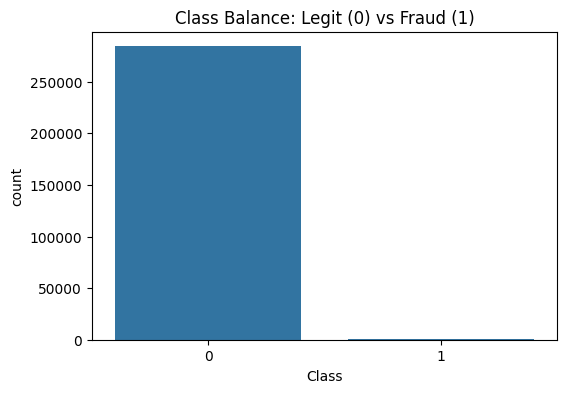

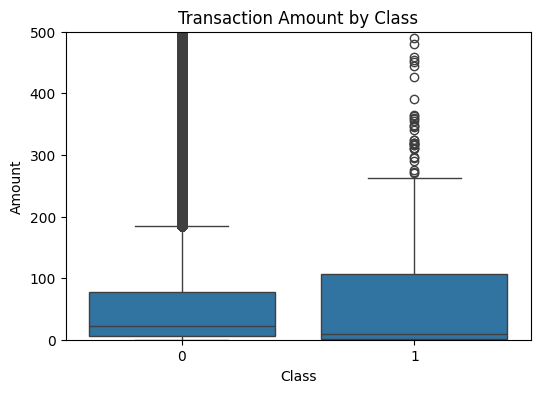

In [2]:
print("Missing values:\n", df.isnull().sum().sum())
print("\nDuplicates:", df.duplicated().sum())
print("\nClass balance:\n", df['Class'].value_counts())
print("\nFraud %:", round(df['Class'].mean()*100, 4), "%")

plt.figure(figsize=(6,4))
sns.countplot(x='Class', data=df)
plt.title("Class Balance: Legit (0) vs Fraud (1)")
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(x='Class', y='Amount', data=df)
plt.title("Transaction Amount by Class")
plt.ylim(0, 500)
plt.show()

In [3]:
df_clean = df.dropna().drop_duplicates()

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_clean['Amount_scaled'] = scaler.fit_transform(df_clean[['Amount']])
df_clean['Time_scaled'] = scaler.fit_transform(df_clean[['Time']])
df_clean = df_clean.drop(['Amount', 'Time'], axis=1)

X = df_clean.drop('Class', axis=1)
y = df_clean['Class']
print("Final shape:", X.shape)

Final shape: (283726, 30)


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

Accuracy: 0.9751876784266732
Precision: 0.05611899932386748
Recall: 0.8736842105263158
F1-score: 0.10546378653113088
ROC-AUC: 0.9658137683266611

Confusion Matrix:
 [[55255  1396]
 [   12    83]]


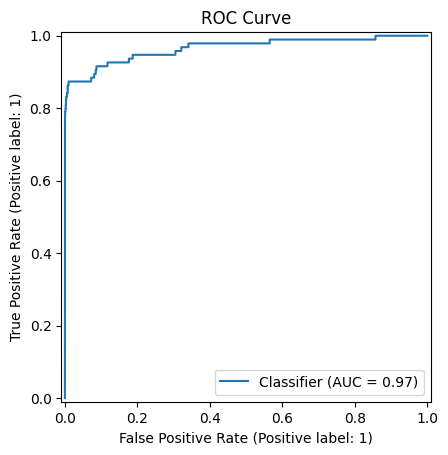

In [5]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, roc_auc_score, RocCurveDisplay)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("ROC Curve")
plt.show()

In [6]:
import joblib
joblib.dump(model, "fraud_model.pkl")
joblib.dump(scaler, "scaler.pkl")
print("Saved model and scaler.")

Saved model and scaler.


In [8]:
from sklearn.preprocessing import StandardScaler
amount_scaler = StandardScaler().fit(df[['Amount']])
time_scaler = StandardScaler().fit(df[['Time']])
joblib.dump(amount_scaler, "amount_scaler.pkl")
joblib.dump(time_scaler, "time_scaler.pkl")
joblib.dump(X.columns.tolist(), "feature_columns.pkl")

sample_df = X_test.copy()
sample_df['Actual'] = y_test.values
sample_df = sample_df.sample(10, random_state=1).reset_index(drop=True)
sample_df.to_csv("sample_transactions.csv", index=False)
print("Saved amount_scaler.pkl, time_scaler.pkl, feature_columns.pkl, sample_transactions.csv")

Saved amount_scaler.pkl, time_scaler.pkl, feature_columns.pkl, sample_transactions.csv


In [11]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

model = joblib.load("fraud_model.pkl")
amount_scaler = joblib.load("amount_scaler.pkl")
time_scaler = joblib.load("time_scaler.pkl")
feature_columns = joblib.load("feature_columns.pkl")

st.title("Payment Transaction Anomaly Classifier")
st.write("Predicts whether a transaction is legitimate or fraudulent (educational prototype).")

mode = st.sidebar.radio("Input mode", ["Use sample transaction", "Manual entry (Amount & Time)"])

if mode == "Use sample transaction":
    samples = pd.read_csv("sample_transactions.csv")
    idx = st.selectbox("Pick a sample transaction", samples.index)
    row = samples.loc[idx]
    if st.button("Predict"):
        features = row[feature_columns].values.reshape(1, -1)
        pred = model.predict(features)[0]
        proba = model.predict_proba(features)[0][1]
        st.write(f"Prediction: {'FRAUD' if pred==1 else 'Legitimate'}")
        st.write(f"Fraud probability: {proba:.4f}")
        st.write(f"Actual label: {'FRAUD' if row['Actual']==1 else 'Legitimate'}")
else:
    amount = st.number_input("Transaction Amount", min_value=0.0, value=50.0)
    time_val = st.number_input("Time (seconds since first transaction)", min_value=0.0, value=10000.0)
    if st.button("Predict"):
        row = {col: 0.0 for col in feature_columns}
        row['Amount_scaled'] = amount_scaler.transform([[amount]])[0][0]
        row['Time_scaled'] = time_scaler.transform([[time_val]])[0][0]
        features = pd.DataFrame([row])[feature_columns].values
        pred = model.predict(features)[0]
        proba = model.predict_proba(features)[0][1]
        st.write(f"Prediction: {'FRAUD' if pred==1 else 'Legitimate'}")
        st.write(f"Fraud probability: {proba:.4f}")

Overwriting app.py
